In [1]:
from multilinear_regression import Multilinear_Regression
from datetime import date, timedelta
import yfinance as yf

## Assumptions of Multi Linear Regression
* Linearity: The relationship between the dependent variable and independent variable is linear
* Homoskedasticity: The variance of the regression residuals is the same for all observations
* Independence of errors: The observations are independent of one another.
* Normality: the regression residuals are normal
* Independence of independent variables: independent variables are not random and no exact linear relation between two ore more variables

In [2]:
universe = "2023-01-01"

In [3]:
symbol_list = ['SPY', '^VIX', '^TNX', 'TIP', 'GLD']

In [4]:
test = Multilinear_Regression(symbol_list = symbol_list, start = universe, end = "2025-01-01", sample_size=100)

YF.download() has changed argument auto_adjust default to True


C:\Users\realg\anaconda3\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
[*********************100%***********************]  5 of 5 completed


--------------------
Using existing sample.csv with 100 data points.
--------------------
Number of Samples: 100


In [5]:
test.return_coefficients(r_table=True)

R-Squared Table:


,,Value
0,Multiple R,0.823174
1,R-Squared,0.677615
2,Adjusted R-Squared,0.664041
3,Standard Error,0.004834
4,Log-Likelihood,393.824274
5,AIC,-1061.565585
6,BIC,-1048.539734
7,Observations,100.000000


In [6]:
test.return_coefficients(anova=True)

ANOVA Table:


,,DF,SS,MS,F
0,Regression,4,0.004665,0.001166,49.919717
1,Residual,95,0.002219,0.000023,
2,Total,99,0.006885,,


In [7]:
test.return_coefficients(coeff=True)

If P-value < 0.05, we can reject the null hypothesis that the coefficient is equal to 0
If P-value > 0.05, we cannot reject the null hypothesis that the coefficient is equal to 0
Coefficients:


,,Coefficent,Standard Error,t Stat,P-value,Lower 95%,Upper 95%
0,Intercept,0.000536,0.000496,1.081170,0.282359,-0.000449,0.001522
1,^VIX,-0.071464,0.005231,-13.662609,0.000000,-0.081848,-0.061080
2,^TNX,0.017295,0.027941,0.618994,0.537402,-0.038174,0.072765
3,TIP,-0.073394,0.133220,-0.550921,0.582981,-0.337869,0.191081
4,GLD,0.173989,0.049559,3.510744,0.000685,0.075602,0.272377


## Linearity

## Homoskedasticity

In [8]:
test.homoscedasticity()

## Independence of errors

Residuals vs Predicted Values Plot
Things to look for in the plot:
If the residuals are randomly scattered around 0, then the model is appropriate for the data
If the residuals show a pattern, then the model is not appropriate for the data
Outliers  can be used to check for influential points that may be affecting the model


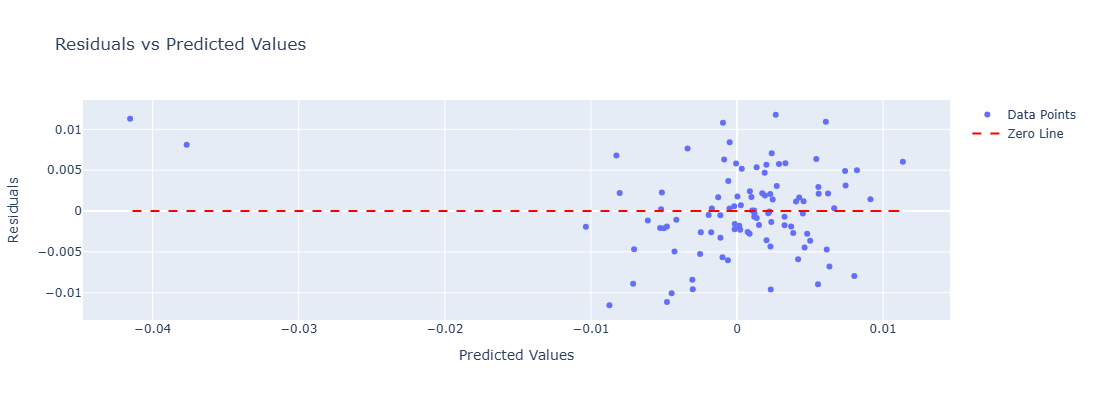

Residuals vs Independent Variables Plot
There is a weak correlation between the predicted values and the actual values, this is good!


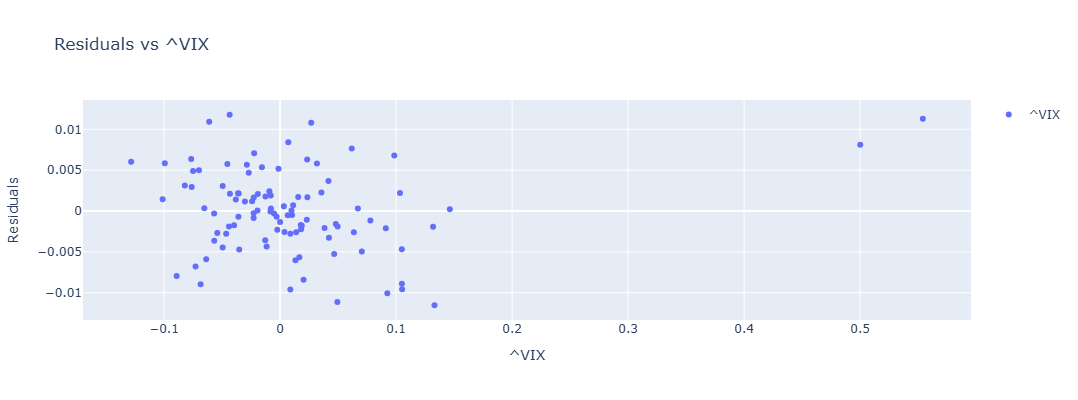

There is a weak correlation between ^VIX and the residuals, this is good!


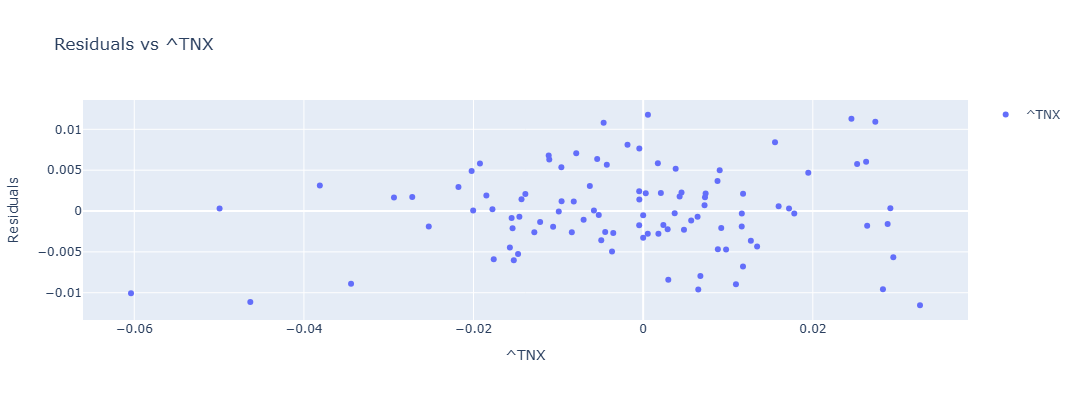

There is a weak correlation between ^TNX and the residuals, this is good!


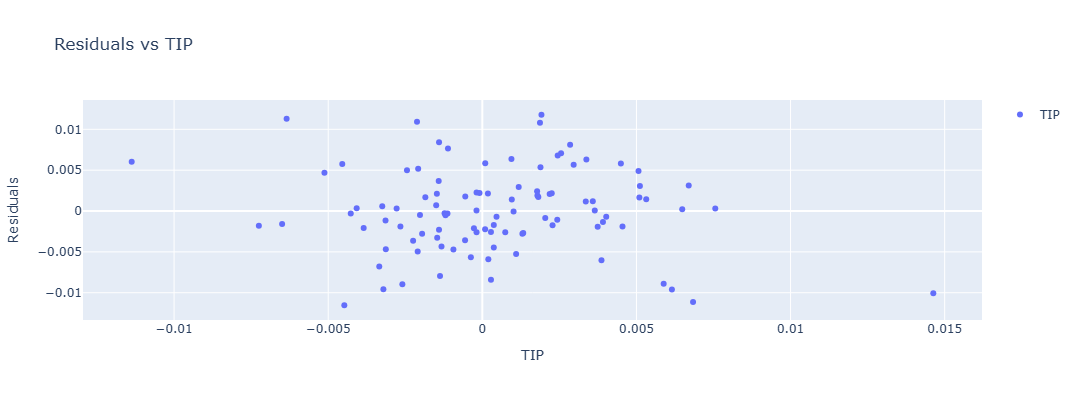

There is a weak correlation between TIP and the residuals, this is good!


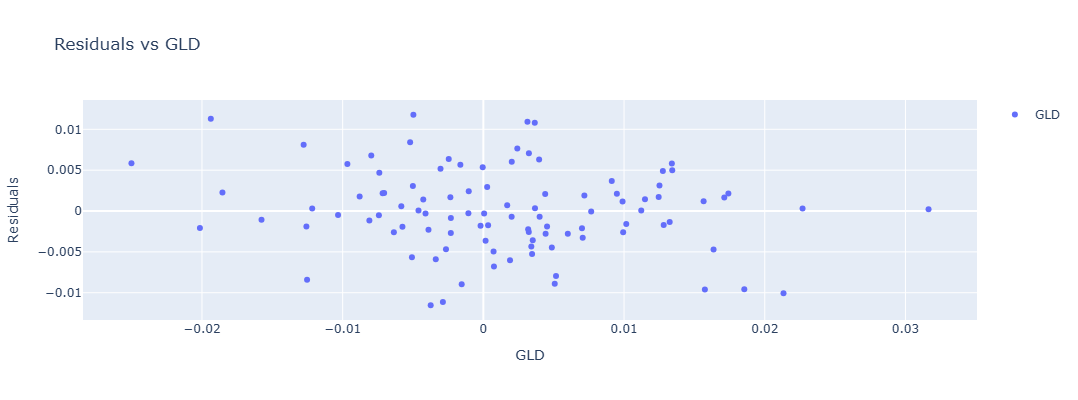

There is a weak correlation between GLD and the residuals, this is good!


In [9]:
test.residual_plots()

## Normality

QQ Plot of Residuals
If the residuals are normally distributed, the points will fall on the line
If observations are far from the line, they may be outliers or influential points that may be affecting the model


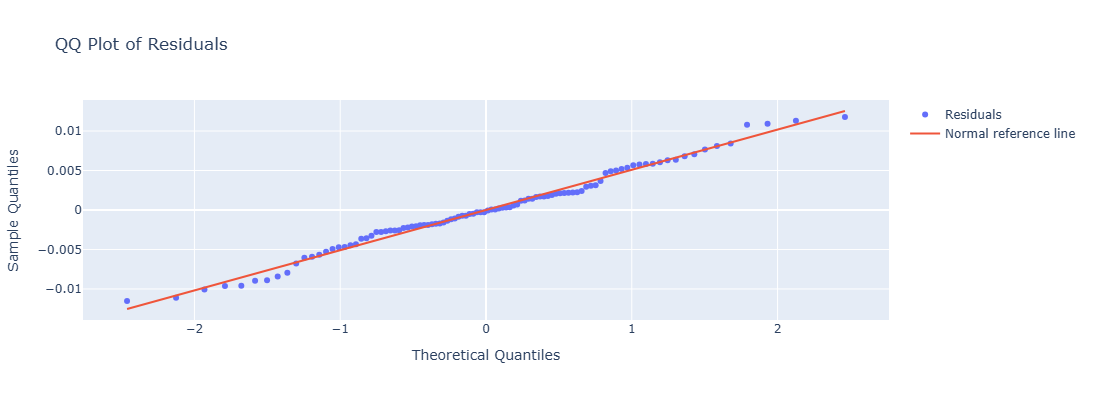

The residuals are not highly skewed, which is good!


In [10]:
test.qq_plot()

## Independence of independent variables

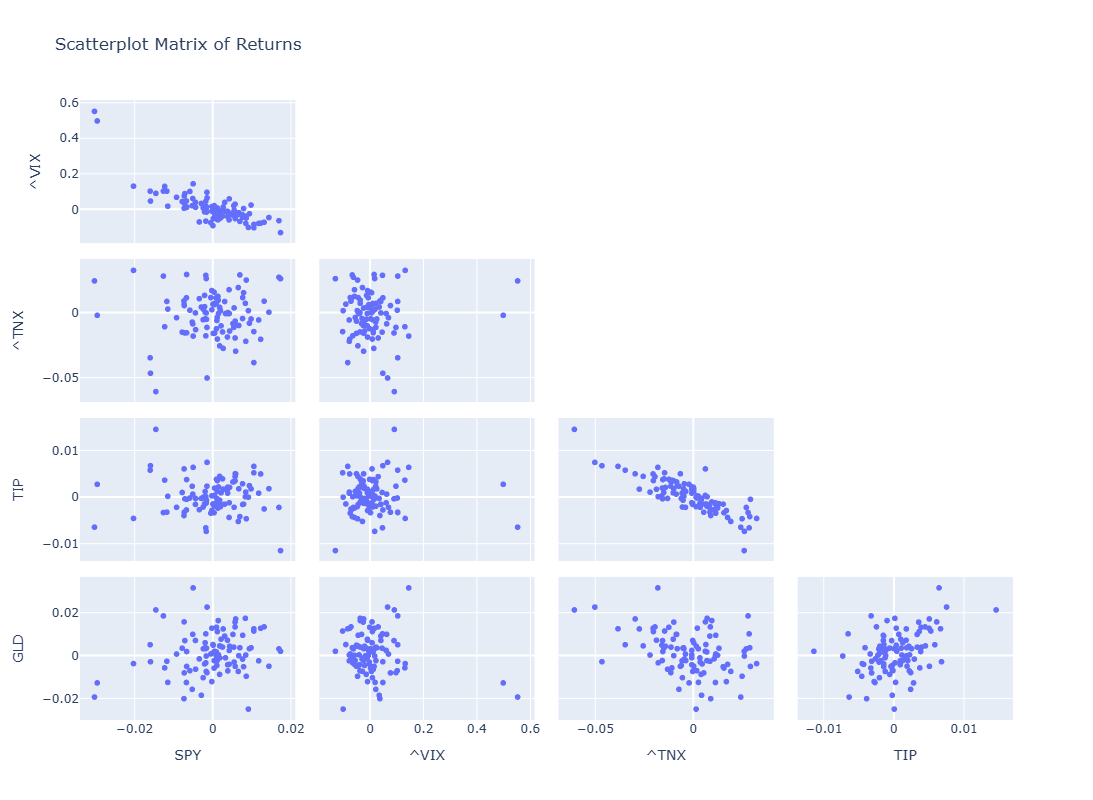

In [11]:
test.scatterplot_matrix()

## Goodness of Fit Examination

Goodness of Fit Table:
Key things to look for in the table:
- Highest R-Squared and Adjusted R-Squared values indicate a better fit
- Lowest AIC and BIC values indicate a better fit
- The magnitude of changes when adding a factor indicates the importance of that factor in explaining the dependent variable


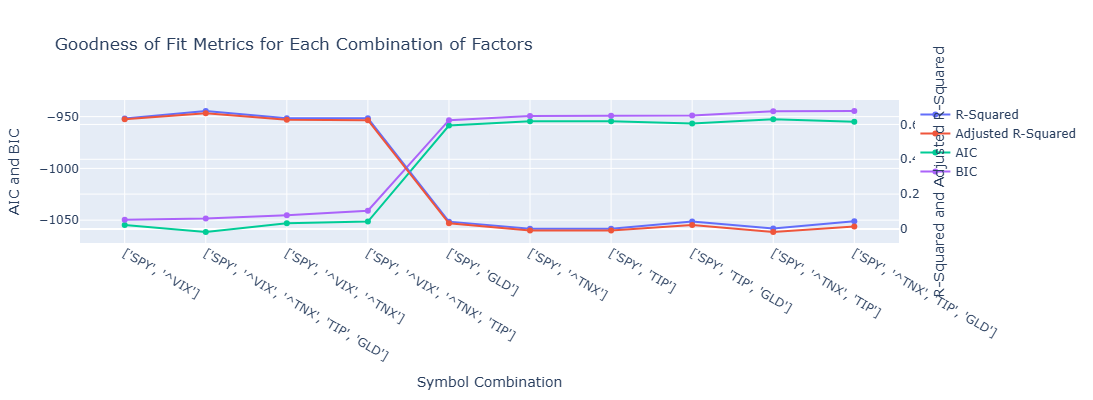

,Symbol Combination,R-Squared,Adjusted R-Squared,AIC,BIC
0,"['SPY', '^VIX']",0.633459,0.629718,-1054.729048,-1049.518707
9,"['SPY', '^VIX', '^TNX', 'TIP', 'GLD']",0.677615,0.664041,-1061.565585,-1048.539734
4,"['SPY', '^VIX', '^TNX']",0.634759,0.627228,-1053.084411,-1045.268900
7,"['SPY', '^VIX', '^TNX', 'TIP']",0.635789,0.624407,-1051.366809,-1040.946128
3,"['SPY', 'GLD']",0.041826,0.032049,-958.637275,-953.426935
1,"['SPY', '^TNX']",0.001300,-0.008891,-954.494764,-949.284424
2,"['SPY', 'TIP']",0.001030,-0.009164,-954.467707,-949.257366
6,"['SPY', 'TIP', 'GLD']",0.042856,0.023121,-956.744827,-948.929317
5,"['SPY', '^TNX', 'TIP']",0.002330,-0.018240,-952.597950,-944.782439
8,"['SPY', '^TNX', 'TIP', 'GLD']",0.044157,0.014286,-954.880766,-944.460085


In [12]:
test.goodness_of_fit()

## Hypothesis Tests

In [13]:
restricted_symbol_list = ['SPY', '^VIX', '^TNX']
test.ht_restricted_model(restricted_symbol_list=restricted_symbol_list)

Hypothesis Test for Restricted Model:
Null Hypothesis: Factors excluded from the restricted model have a slope of 0
Alternative Hypothesis: Atleast one of the excluded factors from the restricted model has a slope not equal to 0
---------------------------------
Critical Value: 3.0922
F-Statistic: 6.3144
---------------------------------
Reject the null hypothesis, the restricted factors both have a slope of 0


,Source,Factors,Degrees of Freedom,SSE,MSE
0,Restricted Model,"[SPY, ^VIX, ^TNX]",97,0.002515,0.000026
1,Unrestricted Model,"[SPY, ^VIX, ^TNX, TIP, GLD]",95,0.002219,0.000023


In [14]:
test.ht_general_linear_f_test()

General Linear F-Test:
Null Hypothesis: All slopes are equal to 0
Alternative Hypothesis: Atleast one slope is not equal to 0
---------------------------------
Critical Value: 2.4675
F-Statistic: 49.9197
---------------------------------
Reject the null hypothesis, atleast one slope is not equal to 0
